# Turtle Breakout 19 — a 1-day reversal rule on the days the BTC turtle is out

Pre-registration: `discussions/Turtle_Breakout/021_claude_tb19_preregistration.md`. Code: `turtle_reversal1d.py`.

**Rule (frozen from TB 18):** at the close of a FLAT day (the TB 01 turtle holds no long), if today's return is at or below the 20th percentile of the previous 365 FLAT days' returns, buy at the close and sell at the next close. Long only. Size = the turtle's 2% risk unit (≤ 3×). 6 bp per side; funding on the perpetual.
**Gates** (each: mean net R above random 1-day longs on FLAT days, p < 0.0167, and mean net return > 0): **G1** Yahoo 2014–2019, **G2** Yahoo 2020–, **G3** Binance BTCUSDT perpetual daily (artefact check). `REVERSAL_EDGE` if all three pass. In-sample confirmation (TB 18 found the pattern on the same data).

Environment: `TB17_DATA` (Yahoo file), `TB01_DATA_DIR` (Binance long folder), `TB19_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_reverse as tr, turtle_stocks as tk, turtle_stock_accounts as ta, turtle_btc_history as bh, turtle_flat_diag as fd, turtle_reversal1d as rv

SYNTHETIC = os.getenv('TB19_SYNTHETIC', '0') == '1'
RP1 = rv.RParams(); BP = bh.BParams()
P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=BP.side_cost - tb.Params().slip); RPt = replace(tr.RParams(), side_cost=BP.side_cost)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb19-')) / '19'; RP1 = replace(RP1, n_null=2000)
    d, _ = tk.synthetic_daily(4400, seed=19, vol=0.04, gap=0.0, steps=48, drift=0.0008); d.index = pd.date_range('2014-09-17', periods=len(d), freq='D'); YH = d
    BN = YH[YH.index >= '2019-09-10'] * np.exp(np.random.default_rng(1).normal(0, 0.002, (len(YH[YH.index >= '2019-09-10']), 1))); BN['high'] = BN[['open', 'high', 'close']].max(axis=1); BN['low'] = BN[['open', 'low', 'close']].min(axis=1)
    BFUND = pd.Series(0.0001, index=BN.index)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '19'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    YF = Path(os.environ.get('TB17_DATA', str(root / 'Stocks' / 'tb17' / 'btc_daily.parquet')))
    if not YF.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb17_btc as dl; YF = dl.download(YF.parent)
    raw = pd.read_parquet(YF); raw['date'] = pd.to_datetime(raw['date']).dt.tz_localize(None).dt.normalize()
    YH = raw.set_index('date')[['open', 'high', 'low', 'close']].sort_index(); YH = YH[~YH.index.duplicated()].dropna(); YH = YH[(YH > 0).all(axis=1)]
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else root / 'Binance'
    BDIR = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    BN = rv.daily_from_1m(pd.read_parquet(BDIR / 'BTCUSDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
    fp = BDIR / 'basis' / 'funding' / 'BTCUSDT_funding.parquet'
    BFUND = rv.daily_funding(tb.funding_events(pd.read_parquet(fp)) if fp.exists() else None, BN.index)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_reversal1d.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print('Yahoo', YH.index[0].date(), '->', YH.index[-1].date(), len(YH), '| Binance daily', BN.index[0].date(), '->', BN.index[-1].date(), len(BN))
print(json.dumps(rv.registration(RP1), indent=1))

OK
Yahoo 2014-09-17 -> 2026-10-27 4424 | Binance daily 2020-01-01 -> 2026-10-23 2488
{
 "quantile": 0.2,
 "lookback_flat_days": 365,
 "min_flat_days": 100,
 "hold": 1,
 "side_cost": 0.0006,
 "side_cost_high": 0.0015,
 "risk_frac": 0.02,
 "pos_cap": 3.0,
 "atr_n": 20,
 "n_null": 10000,
 "alpha": 0.05,
 "n_tests": 3,
 "seed": 20261031,
 "status": "PREREGISTERED_TB021",
 "version": "TB19-0.1.0",
 "gates": {
  "G1": "Yahoo 2014-10..2019-12",
  "G2": "Yahoo 2020-01..end",
  "G3": "Binance perp daily 2019-09..end",
  "each": "mean net R > random FLAT-day 1-day longs (p < alpha/3) and mean net return > 0",
  "verdict": "REVERSAL_EDGE if all three pass, else NO_TRADABLE_REVERSAL"
 },
 "reported": [
  "short leg after top-quintile days",
  "10th / 30th percentile",
  "2-day hold",
  "15 bp costs",
  "account curves; correlation with the turtle; turtle + reversal combined (half capital each)",
  "by year"
 ]
}


## 1. Turtle state, signals, trades and the random-entry pool

In [2]:
def build(daily, funding):
    W = bh.run_window(daily, str(daily.index[0].date()), None, P, RPt, ta.AParams(), 0, np.random.default_rng(0))
    TRl = W['trades'].query("kind == 'long'").copy(); TRl.loc[TRl.open_at_end, 'exit'] = daily.index[-1] + pd.Timedelta(days=1)
    state = fd.turtle_state(daily.index, TRl, W['long'].index[0])
    flat = (state == 'flat'); r = np.log(daily.close).diff()
    return {'daily': daily, 'funding': funding, 'flat': flat, 'r': r, 'turtle': W['long'], 'state': state}
S = {'yahoo': build(YH, None), 'binance': build(BN, BFUND)}
for k, s in S.items():
    s['sig'] = rv.signals(s['r'], s['flat'], RP1)
    s['T'] = rv.trades(s['daily'], s['sig'], RP1, s['funding'])
    s['pool'] = rv.trades(s['daily'], s['flat'] & s['r'].notna(), RP1, s['funding'])
    print(f"{k}: FLAT days {int(s['flat'].sum())}, signals {int(s['sig'].sum())}, trades {len(s['T'])}, pool {len(s['pool'])}")

yahoo: FLAT days 2578, signals 488, trades 488, pool 2577
binance: FLAT days 1471, signals 273, trades 273, pool 1470


## 2. Decision

In [3]:
def cut(T, a, b):
    return T[(T.entry >= pd.Timestamp(a)) & (T.entry <= pd.Timestamp(b))] if len(T) else T
WIN = {'G1': ('yahoo', '2014-01-01', '2019-12-31'), 'G2': ('yahoo', '2020-01-01', '2100-01-01'), 'G3': ('binance', '2019-01-01', '2100-01-01')}
DEC = {}
for j, (g, (src, a, b)) in enumerate(WIN.items()):
    DEC[g] = {'source': src, 'from': a, **rv.gate(cut(S[src]['T'], a, b), cut(S[src]['pool'], a, b), RP1, RP1.seed + j)}
DEC['verdict'] = 'REVERSAL_EDGE' if all(DEC[g]['pass'] for g in WIN) else 'NO_TRADABLE_REVERSAL'
print(json.dumps(DEC, indent=1, default=float))

{
 "G1": {
  "source": "yahoo",
  "from": "2014-01-01",
  "trades": 189,
  "mean_R": 0.02416678255244813,
  "null_mean_R": -0.017243148353435468,
  "null_sd": 0.029438262226244714,
  "p": 0.0744925507449255,
  "mean_ret_pct": 0.5702543681913508,
  "win_rate": 0.5925925925925926,
  "pass": false
 },
 "G2": {
  "source": "yahoo",
  "from": "2020-01-01",
  "trades": 299,
  "mean_R": 0.0140898681990587,
  "null_mean_R": -0.011181447928923414,
  "null_sd": 0.02139807911676616,
  "p": 0.11868813118688132,
  "mean_ret_pct": 0.42453523425669365,
  "win_rate": 0.5518394648829431,
  "pass": false
 },
 "G3": {
  "source": "binance",
  "from": "2019-01-01",
  "trades": 273,
  "mean_R": 0.013991294452208166,
  "null_mean_R": -0.012008238225102915,
  "null_sd": 0.02055732049340685,
  "p": 0.10158984101589841,
  "mean_ret_pct": 0.39414345380354476,
  "win_rate": 0.5604395604395604,
  "pass": false
 },
 "verdict": "NO_TRADABLE_REVERSAL"
}


## 3. Reported: variants, costs, short leg, by year

In [4]:
rows = []
for src in ('yahoo', 'binance'):
    s = S[src]
    variants = {'rule (q=0.2, 1 day)': (s['sig'], 'long', 1, None), 'q=0.1': (rv.signals(s['r'], s['flat'], RP1, q=0.1), 'long', 1, None),
                'q=0.3': (rv.signals(s['r'], s['flat'], RP1, q=0.3), 'long', 1, None), '2-day hold': (s['sig'], 'long', 2, None),
                '15 bp per side': (s['sig'], 'long', 1, RP1.side_cost_high), 'short after top 20%': (rv.signals(s['r'], s['flat'], RP1, side='short'), 'short', 1, None)}
    for name, (sig, side, hold, cost) in variants.items():
        T = rv.trades(s['daily'], sig, RP1, s['funding'], side=side, hold=hold, cost=cost)
        pool = rv.trades(s['daily'], s['flat'] & s['r'].notna(), RP1, s['funding'], side=side, hold=hold, cost=cost)
        for lab, (a, b) in (('2014-19', ('2014-01-01', '2019-12-31')), ('2020-', ('2020-01-01', '2100-01-01'))):
            if src == 'binance' and lab == '2014-19':
                continue
            g = rv.gate(cut(T, a, b), cut(pool, a, b), RP1, 7)
            rows.append({'source': src, 'variant': name, 'window': lab, **{k: g[k] for k in ('trades', 'mean_R', 'null_mean_R', 'p', 'mean_ret_pct', 'win_rate')}})
VAR = pd.DataFrame(rows); display(VAR.round(4))
for src in ('yahoo', 'binance'):
    T = S[src]['T']
    if len(T):
        print(src, 'by year'); display(T.groupby(T.entry.dt.year).agg(trades=('ret', 'size'), mean_ret_pct=('ret', lambda x: 100 * x.mean()), win=('ret', lambda x: (x > 0).mean()), sum_R=('R', 'sum')).round(3))

,source,variant,window,trades,mean_R,null_mean_R,p,mean_ret_pct,win_rate
0,yahoo,"rule (q=0.2, 1 day)",2014-19,189,0.0242,-0.0167,0.0806,0.5703,0.5926
1,yahoo,"rule (q=0.2, 1 day)",2020-,299,0.0141,-0.0116,0.1147,0.4245,0.5518
2,yahoo,q=0.1,2014-19,97,0.0548,-0.0166,0.0361,0.7159,0.6082
3,yahoo,q=0.1,2020-,140,-0.0216,-0.0117,0.6326,0.3208,0.5000
4,yahoo,q=0.3,2014-19,290,0.0062,-0.0168,0.1623,0.3126,0.5586
5,yahoo,q=0.3,2020-,428,-0.0077,-0.0116,0.4181,0.1896,0.5304
6,yahoo,2-day hold,2014-19,189,0.0261,-0.0144,0.1727,0.5294,0.5820
7,yahoo,2-day hold,2020-,299,0.0205,-0.0038,0.2066,0.5277,0.5518
8,yahoo,15 bp per side,2014-19,189,0.0071,-0.0392,0.0541,0.3896,0.5608
9,yahoo,15 bp per side,2020-,299,-0.0065,-0.0354,0.0863,0.2440,0.5385


yahoo by year


,trades,mean_ret_pct,win,sum_R
entry,,,,
2015,19,1.793,0.737,3.508
2016,27,0.683,0.593,1.228
2017,46,1.121,0.609,2.364
2018,60,0.563,0.633,1.829
2019,37,-0.814,0.432,-4.361
2020,32,1.037,0.594,1.145
2021,61,1.366,0.607,5.363
2022,47,-0.071,0.617,-1.631
2023,18,0.498,0.556,1.300


binance by year


,trades,mean_ret_pct,win,sum_R
entry,,,,
2020,7,-0.040,0.857,-0.266
2021,59,1.457,0.644,4.707
2022,49,0.186,0.612,-0.219
2023,18,0.483,0.500,1.184
2024,54,0.289,0.556,0.901
2025,52,0.158,0.519,0.261
2026,34,-0.579,0.382,-2.748


## 4. Accounts: reversal alone, turtle alone, combined (half the capital each)

yahoo | daily correlation reversal vs turtle: +0.000


,cagr,max_dd,calmar,sharpe,vol
reversal,0.013208,-0.12629,0.104583,0.223419,0.045078
turtle,0.299234,-0.245543,1.218664,1.222592,0.157899
combined,0.231485,-0.186985,1.237985,1.227342,0.123219
hold,0.560179,-0.83399,0.671685,0.836645,0.547201


binance | daily correlation reversal vs turtle: -0.000


,cagr,max_dd,calmar,sharpe,vol
reversal,0.010301,-0.101449,0.101536,0.200704,0.039022
turtle,0.131232,-0.147299,0.890919,0.899321,0.100131
combined,0.08034,-0.078187,1.027547,0.887788,0.062213
hold,0.378539,-0.766696,0.493727,0.698238,0.500136


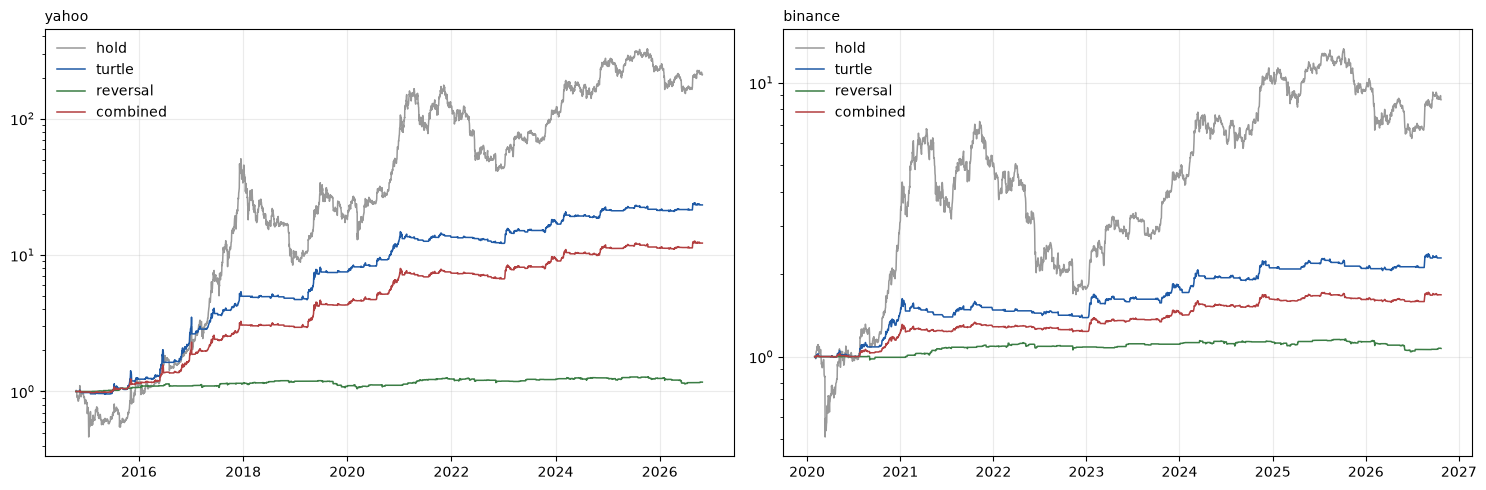

In [5]:
ACC = {}
for src in ('yahoo', 'binance'):
    s = S[src]; days = s['daily'].index
    rev = rv.account(s['T'], days); tur = s['turtle'].reindex(days).ffill().dropna()
    rev = rev.reindex(tur.index)
    comb = 0.5 * rev / rev.iloc[0] + 0.5 * tur / tur.iloc[0]
    hold = s['daily'].close.reindex(tur.index); hold = hold / hold.iloc[0]
    ACC[src] = {'reversal': rev / rev.iloc[0], 'turtle': tur / tur.iloc[0], 'combined': comb, 'hold': hold}
    m = pd.DataFrame({k: tk.metrics(v * 1e5, 1e5) for k, v in ACC[src].items()}).T
    rr = np.log(ACC[src]['reversal']).diff(); rt = np.log(ACC[src]['turtle']).diff()
    print(src, f"| daily correlation reversal vs turtle: {rr.corr(rt):+.3f}"); display(m[['cagr', 'max_dd', 'calmar', 'sharpe', 'vol']].round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, src in zip(axes, ('yahoo', 'binance')):
    for k, col in (('hold', '0.6'), ('turtle', '#1f5aa6'), ('reversal', '#3a7d44'), ('combined', '#b33f40')):
        ax.plot(ACC[src][k].index, ACC[src][k], color=col, label=k, lw=1.1)
    ax.set_yscale('log'); ax.legend(frameon=False); ax.grid(alpha=0.25); ax.set_title(src, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
VAR.to_csv(OUT / '19_variants.csv', index=False)
for src in ('yahoo', 'binance'):
    S[src]['T'].to_csv(OUT / f'19_trades_{src}.csv', index=False)
    pd.DataFrame(ACC[src]).to_csv(OUT / f'19_accounts_{src}.csv')
(OUT / '19_decision.json').write_text(json.dumps({'decision': DEC, 'registration': rv.registration(RP1), 'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '19_manifest.json').write_text(json.dumps({'version': rv.VERSION, 'git': git, 'python': platform.python_version(), 'created_utc': pd.Timestamp.now('UTC').isoformat(), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\19
VERDICT: NO_TRADABLE_REVERSAL
